# Cor Jesu College - Engineering Data Analysis
## Study Habits and Travel to Campus
### Joseph Karl V. Boncavil | BSCoE - 3rd Year
Engineering Data Analysis | Chapters 1-3

This report analyzes **32 actual student responses** collected in the **lobby of Norbert Building**
on **Wednesday, 14 October 2026**. Students who were available and willing were
approached, so the collection method is **convenience sampling**.

The analysis includes frequency distributions, six figures, descriptive statistics,
and a three-page analysis preceded by a cover page. All 32 rows in the supplied response sheet were transcribed
and checked; the 0-minute commute response is retained.

Run all cells using **Kernel > Restart Kernel and Run All Cells**.
The input is [survey_responses.csv](survey_responses.csv); an identical copy is kept
as [survey_dataset.csv](survey_dataset.csv). Outputs are saved in `analysis_output/`.
The complete analysis/report code is embedded below.

Sources: Cor Jesu College applied-exam instructions,
the supplied printed survey instrument, and
Bluman, Elementary Statistics: A Step by Step Approach, 8th edition.

The textbook and instructor-supplied PDFs are classroom reference materials and
are not distributed with the repository. They are not required to rerun the analysis.

## 1. Sample and collection method

**Intended population:** currently enrolled Cor Jesu College undergraduate students
in the Freshman, Sophomore, Junior, and Senior categories. People not enrolled and
students outside those categories are outside the stated scope.

**Sample:** 32 students represented in the supplied response sheet. All 32 records
contain the three required answers; no supplied row was excluded as incomplete.
The dataset does not establish how many additional students declined to participate.

**Collection:** Wednesday, 14 October 2026, in the lobby of Norbert Building. An examination day was deliberately chosen to reach students attending campus.
Available and willing students were approached in person. This is non-probability convenience
sampling: selection probabilities are unknown, and students absent from that
building had no comparable opportunity to participate. It is not a simple random
sample merely because students were approached informally.

**Assignment requirement:** the exam specifies a probability sampling method.
The method actually used is reported here; that requirement is not satisfied by
this convenience sample. A follow-up survey could use a random draw from the
eligible enrollment list, with coverage across year levels and campus locations.

**Recording:** anonymous respondent numbers 1-32 identify the rows. Whole-number
hours and minutes were copied as displayed, without additional rounding. No 8+
answer occurs in this dataset. The enumerator log records the known date, location,
and recruitment method; selection order and undocumented information remain blank.

The questions used by the supplied instrument are:

1. **What is your year level at Cor Jesu College?**
   The analyzed undergraduate categories are Freshman, Sophomore, Junior, and Senior.
2. **On a typical school day, how many hours do you spend studying outside your classes?**
   The form offers 0 through 7 hours and 8 hours or more.
3. **What is your one-way commute time from home to campus, in minutes?**
   The instrument assigns 0 to walking or living on campus. A 0-minute response is
   therefore allowed. Its exact individual reason was not recorded in the table.

### Proposed probability-sampling follow-up

For a subsequent simple random sample, obtain the complete eligible undergraduate
list and assign each student a frame number. Draw 50 distinct numbers using a
random-number generator, recording the seed and invitation list. Invite those
selected students, administer the same three questions, and log nonresponse.
Any additional invitations should be randomly drawn from the remaining frame.
Retain at least 30 complete responses for the required analysis. This is a proposed
follow-up procedure, not a description of how the current 32 students were selected.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 4)

DATA_FILE = Path("survey_responses.csv")
OUTPUT_DIR = Path("analysis_output")

METADATA = {
    "report_type": "survey",
    "population": "Currently enrolled undergraduate students at Cor Jesu College in the Freshman, Sophomore, Junior, and Senior categories.",
    "sampling_method": "convenience",
    "selection_procedure": "An examination day was deliberately chosen to reach students attending campus. Available and willing students in the lobby of Norbert Building were approached in person.",
    "collection_start": "2026-10-14",
    "collection_end": "2026-10-14",
    "decision_question": "What do study-hour patterns and one-way commute times suggest for planning optional study-support sessions?",
    "rounding_rule": "Whole-number hours and minutes were copied from the response sheet without further rounding; no 8+ answer occurs.",
    "recommendation": "Consider study support after existing classes and a remote option for students with longer journeys. Check preferred times before setting a schedule.",
    "vulnerable_assumption": "Convenience sampling at one building may not represent all enrolled undergraduates; sophomores make up half the sample. The exam calls for probability sampling.",
    "next_evidence": "Repeat collection with a probability sample across year levels and campus locations, and ask about preferred study-session times.",
}

COVER_DETAILS = {
    "student_name": "Joseph Karl V. Boncavil",
    "program": "BSCoE",
    "year_section": "3rd Year",
    "institution": "Cor Jesu College",
    "course": "Engineering Data Analysis",
    "course_code": "",
    "instructor": "Engr. Jamie Eduardo Rosal, MSCpE",
    "submission_date": "",
}
METADATA["cover"] = COVER_DETAILS

print("Dataset:", DATA_FILE)
print("Collection:", METADATA["collection_start"], "in the lobby of Norbert Building")
print("Sampling method:", METADATA["sampling_method"])
print("Output directory:", OUTPUT_DIR)

Dataset: survey_responses.csv
Collection: 2026-10-14 in the lobby of Norbert Building
Sampling method: convenience
Output directory: analysis_output


## 2. Population, sample, parameters, statistics, and data dictionary

The **target population** is the defined undergraduate population. The **sample**
consists of the 32 students whose complete responses are in the supplied sheet.
The statistics below describe these respondents; the recruitment method limits
inference to the wider student population.

**Parameters of interest** are the population proportions in each year-level category,
mean daily study hours, and mean and selected quantiles of recorded one-way commute
minutes. **Statistics** are the corresponding proportions, means, medians, modes,
sample variances and standard deviations, quartiles, and percentiles calculated from
the retained responses. These are descriptive summaries; this assignment does not
establish causal effects or estimate uncertainty with confidence intervals.

Q1 is categorical and ordinal, ordered from Freshman through Senior. Q2 is discrete with ratio-scale hour
units, with a top-coded final response. Q3 is continuous with ratio-scale minute
units even though recorded to whole minutes. Respondent number is an identifier,
not a fourth survey question.

In [2]:
dictionary = pd.read_csv("data_dictionary.csv").fillna("")
display(dictionary)

,variable,definition_or_question,variable_type,measurement_level,unit,allowed_values_or_rule
0,respondent_id,Anonymous form number; no name or student number,Identifier,Nominal,,Unique positive whole number; one row per administered form
1,year_level,What is your year level at Cor Jesu College?,Categorical ordinal,Ordinal,Year-level category,Freshman; Sophomore; Junior; Senior (undergraduate study population)
2,study_hours,"On a typical school day, how many hours do you spend studying outside your classes?",Quantitative discrete; the final option is top-coded,Ratio for hours; 8+ is a lower bound,Hours per typical school day,0; 1; 2; 3; 4; 5; 6; 7; 8+ (enter 8+ for the 8 or more response)
3,commute_minutes,"What is your one-way commute time from home to campus, in minutes?","Quantitative continuous, recorded to whole minutes",Ratio,Minutes one way,"Nonnegative whole number; record 0 for walking or living on campus, following the surv..."


## 3. Load and inspect the raw CSV before analysis

Read the raw cells as strings to preserve `8+` and make validation explicit.
Print shape, data types, and missing counts first, as required by the exam.
Blank/whitespace cells count as missing; values such as `NA` are later checked
as invalid responses rather than silently converted to a number.

In [3]:
raw_data = pd.read_csv(DATA_FILE, dtype=str, keep_default_na=False)
print("Raw shape (rows, columns):", raw_data.shape)
print("\nRaw data types:")
print(raw_data.dtypes)
print("\nMissing values by column:")
print(raw_data.replace(r"^\s*$", pd.NA, regex=True).isna().sum())
display(raw_data)

Raw shape (rows, columns): (32, 4)

Raw data types:
respondent_id      object
year_level         object
study_hours        object
commute_minutes    object
dtype: object

Missing values by column:
respondent_id      0
year_level         0
study_hours        0
commute_minutes    0
dtype: int64


,respondent_id,year_level,study_hours,commute_minutes
0,1,Senior,4,25
1,2,Junior,2,12
2,3,Sophomore,1,25
3,4,Freshman,5,45
4,5,Sophomore,2,18
5,6,Senior,1,15
6,7,Senior,3,30
7,8,Sophomore,3,25
8,9,Freshman,5,30
9,10,Senior,2,30


## 4. Reproducible analysis functions

The following cell contains the complete analysis code, including `value_counts()`,
`pd.cut()`, NumPy statistics, and Matplotlib charts. It is included so this notebook
can be rerun without importing a separate local Python module.

No missing values are imputed. Incomplete or invalid rows are excluded with reasons.
All rows sharing a respondent ID are flagged for correction; matching answers from
different IDs are retained. The original CSV is never edited. Legitimate outliers
are retained. No response in the current dataset uses the open-ended `8+` category.

In [4]:
"""Audit and summarize the anonymous Cor Jesu survey without inventing responses.

Study responses are recorded scores: 8 represents the open-ended answer 8+.
Quantiles use linear interpolation, equivalent to spreadsheet INC functions.
"""

from decimal import Decimal, InvalidOperation
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


REQUIRED_COLUMNS = ("respondent_id", "year_level", "study_hours", "commute_minutes")
YEAR_LEVELS = ("Freshman", "Sophomore", "Junior", "Senior")
STUDY_BOUNDARIES = np.array([-0.5, 1.5, 3.5, 5.5, 7.5, 9.5])
STUDY_LABELS = ["0–1", "2–3", "4–5", "6–7", "8–9 (score 8 = 8+)"]
GROUP_COLUMNS = [
    "class_interval", "lower_boundary", "upper_boundary", "midpoint",
    "frequency", "relative_frequency", "percent", "cumulative_frequency",
    "cumulative_relative_frequency",
]
NUMERIC_COLUMNS = ("study_hours", "commute_minutes")


def _whole_number(value):
    """Parse a finite whole number; Decimal avoids merging distinct large IDs."""
    try:
        number = Decimal(str(value).strip())
        if not number.is_finite() or number != number.to_integral_value():
            return None
        if not math.isfinite(float(number)):
            return None
        return int(number)
    except (InvalidOperation, ValueError, OverflowError):
        return None


def _frequency_columns(counts, n):
    counts = np.asarray(counts, dtype=int)
    relative = counts / n if n else np.zeros(len(counts))
    return {
        "frequency": counts,
        "relative_frequency": relative,
        "percent": relative * 100,
        "cumulative_frequency": counts.cumsum(),
        "cumulative_relative_frequency": relative.cumsum(),
    }


def _grouped_table(values, boundaries, labels):
    """Use explicit equal-width classes, retaining classes with zero responses."""
    groups = pd.cut(values, bins=boundaries, labels=labels, include_lowest=True)
    counts = pd.Series(groups).value_counts(sort=False).reindex(labels, fill_value=0)
    return pd.DataFrame({
        "class_interval": labels,
        "lower_boundary": boundaries[:-1],
        "upper_boundary": boundaries[1:],
        "midpoint": (boundaries[:-1] + boundaries[1:]) / 2,
        **_frequency_columns(counts.to_numpy(), len(values)),
    })


def _statistics(values):
    values = np.asarray(values, dtype=float)
    q1, q3, p10, p90 = np.quantile(values, [.25, .75, .1, .9], method="linear")
    distinct, counts = np.unique(values, return_counts=True)
    modes = (
        ", ".join(f"{x:g}" for x in distinct[counts == counts.max()])
        if counts.max() > 1 else "No mode (all values occur once)"
    )
    iqr = q3 - q1
    return {
        "mean": float(np.mean(values)),
        "median": float(np.median(values)),
        "modes": modes,
        "minimum": float(np.min(values)),
        "maximum": float(np.max(values)),
        "range": float(np.max(values) - np.min(values)),
        "sample_variance": float(np.var(values, ddof=1)) if len(values) > 1 else np.nan,
        "sample_sd": float(np.std(values, ddof=1)) if len(values) > 1 else np.nan,
        "q1": float(q1),
        "q3": float(q3),
        "iqr": float(iqr),
        "p10": float(p10),
        "p90": float(p90),
        "lower_fence": float(q1 - 1.5 * iqr),
        "upper_fence": float(q3 + 1.5 * iqr),
    }


def _shape(values, capped=False):
    values = np.asarray(values, dtype=float)
    caveat = (
        " This describes recorded scores; the 8+ cap can hide the upper tail of actual hours."
        if capped else " This describes this sample, not the whole student population."
    )
    if np.ptp(values) == 0:
        return "Constant: all recorded values are equal; skewness is undefined." + caveat
    if len(values) < 3:
        return "Too few observations to assess distribution shape reliably." + caveat
    centered = values - values.mean()
    skewness = float(np.mean((centered / np.sqrt(np.mean(centered ** 2))) ** 3))
    if skewness > .5:
        description = "The recorded distribution shows right skew"
    elif skewness < -.5:
        description = "The recorded distribution shows left skew"
    else:
        description = "The recorded distribution has no strong moment skew"
    return (
        f"{description} (moment skewness {skewness:.3f}; descriptive threshold ±0.5). "
        "Use the plot to check clusters and unusual values; this is not a normality test."
        + caveat
    )


def _make_figures(valid, tables):
    n = len(valid)
    figures = {}
    color = "#225e7a"
    has_cap = bool(valid["study_hours"].eq(8).any())
    study_title = "Recorded study scores" if has_cap else "Daily study hours"
    study_units = "Recorded study score (hours per typical school day; 8 means 8+)" if has_cap else "Study time outside classes (hours per typical school day)"

    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    table = tables["q1"]
    bars = ax.bar(table["category"], table["frequency"], color=color)
    ax.bar_label(bars, padding=3)
    ax.set(title=f"Q1: Year-level distribution (n = {n})",
           xlabel="Year-level category", ylabel="Frequency (records)")
    ax.set_xticks(range(len(YEAR_LEVELS)), YEAR_LEVELS)
    ax.set_ylim(0, max(1, int(table["frequency"].max())) * 1.18)
    ax.yaxis.get_major_locator().set_params(integer=True)
    figures["q1_year_level_bar"] = fig

    table = tables["q2"]
    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    ax.hist(valid["study_hours"], bins=STUDY_BOUNDARIES, color=color, edgecolor="white")
    ax.set(title=f"Q2: {study_title} (n = {n})",
           xlabel=study_units,
           ylabel="Frequency (records)")
    ax.set_xticks(table["midpoint"], table["class_interval"])
    ax.yaxis.get_major_locator().set_params(integer=True)
    fig.text(.5, -.025, "Equal class width = 2 hours. " + ("The final class contains capped score 8, not measured hours 8–9." if has_cap else "Zero-frequency classes are retained."),
             ha="center", fontsize=9)
    figures["q2_study_histogram"] = fig

    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    midpoints = table["midpoint"].to_numpy()
    ax.plot(np.r_[midpoints[0] - 2, midpoints, midpoints[-1] + 2],
            np.r_[0, table["frequency"], 0], marker="o", color=color)
    ax.set(title=f"Q2: Study-hour frequency polygon (n = {n})",
           xlabel="Recorded score class midpoint (hours; score 8 means 8+)" if has_cap else "Study-hour class midpoint (hours)",
           ylabel="Frequency (records)")
    ax.set_xticks(midpoints)
    ax.set_ylim(bottom=0)
    ax.yaxis.get_major_locator().set_params(integer=True)
    fig.text(.5, -.025, ("Midpoint 8.5 represents the capped-score class. " if has_cap else "") + "Zero endpoints close the polygon.",
             ha="center", fontsize=9)
    figures["q2_frequency_polygon"] = fig

    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    ax.plot(STUDY_BOUNDARIES, np.r_[0, table["cumulative_frequency"]], marker="o", color=color)
    ax.set(title=f"Q2: Cumulative study-hour frequency (n = {n})",
           xlabel="Recorded score class boundary (hours; score 8 means 8+)" if has_cap else "Study-hour class boundary (hours)",
           ylabel="Cumulative frequency (records)", ylim=(0, max(1, n) * 1.08))
    ax.set_xticks(STUDY_BOUNDARIES)
    ax.yaxis.get_major_locator().set_params(integer=True)
    fig.text(.5, -.025, "Starts at zero below the first class. " + ("Boundary 9.5 ends a score class, not actual study hours." if has_cap else "The final cumulative frequency equals the sample size."),
             ha="center", fontsize=9)
    figures["q2_ogive"] = fig

    table = tables["q3"]
    boundaries = np.r_[table["lower_boundary"], table["upper_boundary"].iloc[-1]]
    width = table["upper_boundary"].iloc[0] - table["lower_boundary"].iloc[0]
    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    ax.hist(valid["commute_minutes"], bins=boundaries, color=color, edgecolor="white")
    ax.set(title=f"Q3: One-way commute time (n = {n}; class width = {width:g} min)",
           xlabel="Recorded one-way commute time (minutes)", ylabel="Frequency (records)")
    ax.yaxis.get_major_locator().set_params(integer=True)
    fig.text(.5, -.025, "Whole-minute observations use continuous boundaries ±0.5 minute; −0.5 includes recorded zero.",
             ha="center", fontsize=9)
    figures["q3_commute_histogram"] = fig

    fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
    ax.boxplot(valid["commute_minutes"].to_numpy(dtype=float), vert=False, whis=1.5,
               patch_artist=True, boxprops={"facecolor": "#b9d8e5"},
               medianprops={"color": "#a24724", "linewidth": 2})
    ax.set(title=f"Q3: One-way commute time boxplot (n = {n})",
           xlabel="Recorded one-way commute time (minutes)", ylabel="Dataset")
    ax.set_yticks([1], ["Records"])
    fig.text(.5, -.025, "Whiskers reach the furthest observations within the 1.5 × IQR fences; flagged points remain in the data.",
             ha="center", fontsize=9)
    figures["q3_commute_boxplot"] = fig
    return figures


def analyze(csv_path, output_dir=None):
    """Return audited data, tables, descriptive statistics, and six chart figures.

    Input uses REQUIRED_COLUMNS. Raw cell strings are retained unchanged; a
    stripped copy is used for validation. Invalid rows, including *every* row
    sharing a numeric respondent ID, are excluded and recorded with reasons.
    Equal answer triples belonging to different IDs are legitimate responses.
    No files are written unless output_dir is supplied. Outliers are retained.
    """
    issues = []
    try:
        raw = pd.read_csv(csv_path, dtype=str, keep_default_na=False)
    except (OSError, pd.errors.EmptyDataError, pd.errors.ParserError, UnicodeError) as exc:
        raw = pd.DataFrame(columns=REQUIRED_COLUMNS)
        issues.append(f"Could not read survey CSV: {exc}")

    missing_columns = [name for name in REQUIRED_COLUMNS if name not in raw.columns]
    reasons = [[] for _ in range(len(raw))]
    cleaned = []
    id_rows = {}
    if missing_columns:
        message = "Missing required columns: " + ", ".join(missing_columns)
        issues.append(message)
        for row_reasons in reasons:
            row_reasons.append(message)
    else:
        for position, (_, row) in enumerate(raw.iterrows()):
            cells = {name: str(row[name]).strip() for name in REQUIRED_COLUMNS}
            for name, value in cells.items():
                if not value:
                    reasons[position].append(f"{name}: missing value")

            respondent_id = _whole_number(cells["respondent_id"])
            if respondent_id is None or respondent_id <= 0:
                if cells["respondent_id"]:
                    reasons[position].append("respondent_id: must be a positive whole number")
            else:
                id_rows.setdefault(respondent_id, []).append(position)

            year = cells["year_level"]
            if year and year not in YEAR_LEVELS:
                reasons[position].append("year_level: outside the four year-level categories in the study population")

            study_text = cells["study_hours"]
            study = 8 if study_text in ("8+", "8 or more") else _whole_number(study_text)
            if study is None or not 0 <= study <= 8:
                if study_text:
                    reasons[position].append("study_hours: use whole scores 0–7 or 8 / 8+ / 8 or more")

            commute = _whole_number(cells["commute_minutes"])
            if commute is None or commute < 0:
                if cells["commute_minutes"]:
                    reasons[position].append("commute_minutes: must be a finite nonnegative whole number")
            cleaned.append({"respondent_id": respondent_id, "year_level": year,
                            "study_hours": study, "commute_minutes": commute})

        for respondent_id, positions in id_rows.items():
            if len(positions) > 1:
                for position in positions:
                    reasons[position].append(f"respondent_id: duplicate numeric ID {respondent_id}; all copies excluded")

    excluded_positions = [i for i, row_reasons in enumerate(reasons) if row_reasons]
    excluded = raw.iloc[excluded_positions].copy()
    excluded["source_row"] = [i + 2 for i in excluded_positions]
    excluded["reason"] = ["; ".join(reasons[i]) for i in excluded_positions]
    excluded.reset_index(drop=True, inplace=True)
    valid = pd.DataFrame(
        [row for i, row in enumerate(cleaned) if not reasons[i]], columns=REQUIRED_COLUMNS
    )
    n = len(valid)
    if excluded_positions:
        issues.append(f"Excluded {len(excluded_positions)} of {len(raw)} submitted rows; inspect excluded rows and reasons.")
    if n == 0:
        issues.append("No valid responses are available. Collect or correct actual survey data before interpreting results.")
    elif n == 1:
        issues.append("Only one valid response: sample variance and sample standard deviation are undefined.")

    topcoded_count = int((valid["study_hours"] == 8).sum())
    if topcoded_count:
        issues.append(
            "Study hours are recorded capped scores: every 8 / 8+ / 8 or more is coded 8, meaning at least 8 hours. "
            f"Valid top-coded responses: {topcoded_count}. Study summaries describe these scores; "
            "the actual mean and upper tail cannot be recovered when capped responses occur."
        )
    elif n:
        issues.append("All study-hour responses are finite whole-hour values; no open-ended answer occurs.")
    study_labels = STUDY_LABELS if topcoded_count else [f"{2 * i}–{2 * i + 1}" for i in range(5)]
    year_counts = valid["year_level"].value_counts().reindex(YEAR_LEVELS, fill_value=0)
    tables = {
        "q1": pd.DataFrame({"category": YEAR_LEVELS, **_frequency_columns(year_counts.to_numpy(), n)}),
        "q2": _grouped_table(valid["study_hours"], STUDY_BOUNDARIES, study_labels),
        "q3": pd.DataFrame(columns=GROUP_COLUMNS),
    }
    stats = pd.DataFrame(columns=NUMERIC_COLUMNS)
    stats.index.name = "metric"
    shapes = {"q2": "No valid observations.", "q3": "No valid observations."}
    outliers = {name: [] for name in NUMERIC_COLUMNS}
    figures = {}
    if n:
        max_minutes = int(valid["commute_minutes"].max())
        target_classes = max(1, math.ceil(1 + math.log2(n)))
        width = max(1, math.ceil((max_minutes + 1) / target_classes))
        class_count = (max_minutes // width) + 1
        boundaries = np.arange(class_count + 1, dtype=float) * width - .5
        labels = [f"{i * width}–{(i + 1) * width - 1}" for i in range(class_count)]
        tables["q3"] = _grouped_table(valid["commute_minutes"], boundaries, labels)
        issues.append(
            f"Q3 uses equal-width classes of {width} minute(s), starting at recorded zero; "
            f"target class count = ceil(1 + log2(n)) = {target_classes}. "
            "Real boundaries are whole-minute limits ±0.5; the −0.5 boundary includes zero, not negative travel."
        )
        stats = pd.DataFrame({name: _statistics(valid[name]) for name in NUMERIC_COLUMNS})
        stats.index.name = "metric"
        for name in NUMERIC_COLUMNS:
            mask = ((valid[name] < stats.at["lower_fence", name]) |
                    (valid[name] > stats.at["upper_fence", name]))
            outliers[name] = valid.loc[mask, "respondent_id"].tolist()
        shapes = {"q2": _shape(valid["study_hours"], capped=bool(topcoded_count)),
                  "q3": _shape(valid["commute_minutes"])}
        figures = _make_figures(valid, tables)

    result = {"raw": raw, "valid": valid, "excluded": excluded, "issues": issues,
              "n": n, "tables": tables, "statistics": stats, "outliers": outliers,
              "topcoded_count": topcoded_count, "shapes": shapes, "figures": figures}
    if output_dir is not None:
        destination = Path(output_dir)
        destination.mkdir(parents=True, exist_ok=True)
        raw.to_csv(destination / "raw_responses.csv", index=False)
        valid.to_csv(destination / "valid_responses.csv", index=False)
        excluded.to_csv(destination / "excluded_responses.csv", index=False)
        for name, table in tables.items():
            table.to_csv(destination / f"{name}_frequency_table.csv", index=False)
        stats.to_csv(destination / "descriptive_statistics.csv")
        pd.DataFrame({"issue_or_note": issues}).to_csv(destination / "validation_notes.csv", index=False)
        pd.DataFrame([
            {"variable": name, "respondent_id": respondent_id}
            for name, ids in outliers.items() for respondent_id in ids
        ], columns=["variable", "respondent_id"]).to_csv(destination / "outlier_flags.csv", index=False)
        for name, fig in figures.items():
            fig.savefig(destination / f"{name}.png", dpi=180, bbox_inches="tight")
    return result

In [5]:
result = analyze(DATA_FILE, output_dir=OUTPUT_DIR)
plt.close("all")  # keep figure objects for deliberate display/export below

print("Retained records:", result["n"])
print("Excluded records:", len(result["excluded"]))
for issue in result["issues"]:
    print("•", issue)
if not result["excluded"].empty:
    display(result["excluded"])
if result["n"] < 30:
    print("At least 30 complete records are required. Current analysis is preliminary.")
display(result["valid"])

Retained records: 32
Excluded records: 0
• All study-hour responses are finite whole-hour values; no open-ended answer occurs.
• Q3 uses equal-width classes of 10 minute(s), starting at recorded zero; target class count = ceil(1 + log2(n)) = 6. Real boundaries are whole-minute limits ±0.5; the −0.5 boundary includes zero, not negative travel.


,respondent_id,year_level,study_hours,commute_minutes
0,1,Senior,4,25
1,2,Junior,2,12
2,3,Sophomore,1,25
3,4,Freshman,5,45
4,5,Sophomore,2,18
5,6,Senior,1,15
6,7,Senior,3,30
7,8,Sophomore,3,25
8,9,Freshman,5,30
9,10,Senior,2,30


## 5. Chapter 2 - frequency distributions and shapes

Every table shows frequencies and relative frequencies, retaining zero-count classes.
Q1 uses the four ordered undergraduate categories.

**Q2:** classes are 0-1, 2-3, 4-5, 6-7, and 8-9 hours, with class width 2 hours,
real boundaries -0.5, 1.5, 3.5, 5.5, 7.5, 9.5, and midpoints 0.5, 2.5, 4.5,
6.5, 8.5 hours. The observed answers range from 0 to 5 hours, so the final two
classes have zero frequency. No top-coding affects the present calculations.

**Q3:** Sturges' heuristic gives six classes; the resulting whole-minute width is
10 minutes. The classes are 0-9, 10-19, 20-29, 30-39, 40-49, and 50-59 minutes.
Their continuous boundaries are -0.5, 9.5, ..., 59.5; the first boundary includes
recorded zero and does not imply negative travel time.

Sturges' rule is a chosen class-count heuristic, not Bluman's prescribed rule.
All classes are equal-width, exhaustive, and nonoverlapping. Statistics are
calculated from individual observations, not from these class midpoints.

In [6]:
for label, key in [("Q1 — Year level", "q1"), ("Q2 — Recorded study score", "q2"), ("Q3 — One-way commute minutes", "q3")]:
    display(Markdown("### " + label))
    display(result["tables"][key])

if result["n"]:
    q1 = result["tables"]["q1"]
    highest = q1["frequency"].max()
    common = ", ".join(q1.loc[q1["frequency"].eq(highest), "category"])
    absent = q1.loc[q1["frequency"].eq(0), "category"].tolist()
    label = "retained records"
    display(Markdown(
        f"**Dataset size:** {result['n']} {label}. **Q1:** the most common year level(s): "
        f"{common}, with {highest} records each. "
        + ("Absent categories: " + ", ".join(absent) + "." if absent else "All four year-level categories are represented.")
        + " Representation alone does not establish an unbiased sample."
    ))
    q3 = result["tables"]["q3"]
    print("Q2 score class width: 2 hours; Q3 class width:", q3.iloc[0]["upper_boundary"] - q3.iloc[0]["lower_boundary"], "minutes")
    display(Markdown("**Q2 shape:** " + result["shapes"]["q2"] + "\n\n**Q3 shape:** " + result["shapes"]["q3"]))

### Q1 — Year level

,category,frequency,relative_frequency,percent,cumulative_frequency,cumulative_relative_frequency
0,Freshman,5,0.1562,15.625,5,0.1562
1,Sophomore,16,0.5000,50.000,21,0.6562
2,Junior,4,0.1250,12.500,25,0.7812
3,Senior,7,0.2188,21.875,32,1.0000


### Q2 — Recorded study score

,class_interval,lower_boundary,upper_boundary,midpoint,frequency,relative_frequency,percent,cumulative_frequency,cumulative_relative_frequency
0,0–1,-0.5,1.5,0.5,11,0.3438,34.375,11,0.3438
1,2–3,1.5,3.5,2.5,13,0.4062,40.625,24,0.7500
2,4–5,3.5,5.5,4.5,8,0.2500,25.000,32,1.0000
3,6–7,5.5,7.5,6.5,0,0.0000,0.000,32,1.0000
4,8–9,7.5,9.5,8.5,0,0.0000,0.000,32,1.0000


### Q3 — One-way commute minutes

,class_interval,lower_boundary,upper_boundary,midpoint,frequency,relative_frequency,percent,cumulative_frequency,cumulative_relative_frequency
0,0–9,-0.5,9.5,4.5,2,0.0625,6.250,2,0.0625
1,10–19,9.5,19.5,14.5,5,0.1562,15.625,7,0.2188
2,20–29,19.5,29.5,24.5,14,0.4375,43.750,21,0.6562
3,30–39,29.5,39.5,34.5,5,0.1562,15.625,26,0.8125
4,40–49,39.5,49.5,44.5,5,0.1562,15.625,31,0.9688
5,50–59,49.5,59.5,54.5,1,0.0312,3.125,32,1.0000


**Dataset size:** 32 retained records. **Q1:** the most common year level(s): Sophomore, with 16 records each. All four year-level categories are represented. Representation alone does not establish an unbiased sample.

Q2 score class width: 2 hours; Q3 class width: 10.0 minutes


**Q2 shape:** The recorded distribution has no strong moment skew (moment skewness 0.217; descriptive threshold ±0.5). Use the plot to check clusters and unusual values; this is not a normality test. This describes this sample, not the whole student population.

**Q3 shape:** The recorded distribution has no strong moment skew (moment skewness 0.382; descriptive threshold ±0.5). Use the plot to check clusters and unusual values; this is not a normality test. This describes this sample, not the whole student population.

## 6. Chapter 3 — center, spread, position, and outliers for BOTH numeric variables

Statistics use individual recorded observations, not grouped-class midpoints.
`ddof=1` applies to sample variance and sample standard deviation only. Quartiles
and P10/P90 use NumPy's inclusive linear interpolation, matching spreadsheet
`QUARTILE.INC` / `PERCENTILE.INC`. Report every tied mode; if all values occur once,
report no mode.

**Textbook convention check:** Bluman §3–3, printed pp. 148–149, describes a hand
percentile rule based on `c = n × p / 100`: round a noninteger c upward, or average
positions c and c+1 when c is an integer. Printed p. 150 describes quartiles using
medians of the lower and upper halves. These can differ from inclusive linear
software quantiles. This notebook consistently uses the software convention to
match the exam's specified Sheets INC functions across tool tracks; it does not
claim that this is Bluman's hand-calculation algorithm.

Mean, median, range, SD, quartiles, IQR, percentiles, and fences use **hours** for
study time and **minutes** for commute. Variance uses **hours²** or
**minutes²**. No `8+` answer occurs in the current dataset, so no top-coding adjustment is needed.

Outlier fences are Q1 − 1.5×IQR and Q3 + 1.5×IQR. Values **strictly** outside the
fences are flagged, not automatically deleted. Boxplot whiskers end at observed
values within the fences, not at the fence numbers themselves.
This is the modified Tukey boxplot convention. Bluman's simple boxplot construction
in §3–4, printed pp. 162–163, instead places whiskers at the minimum and maximum.
The modified plot used here displays the assignment's separately required IQR outlier flags.

For commute time, the IQR fences are 5 and 45 minutes. Respondent 24 (55 minutes)
and respondent 30 (0 minutes) fall outside those fences. Both are retained.
The zero value is permitted by the instrument; an outlier flag does not imply
an error. Values exactly at 5 or 45 minutes are not flagged.

In [7]:
if result["n"]:
    summary = result["statistics"].copy()
    summary.columns = ["Study time (hours)", "One-way commute (minutes)"]
    summary["unit_note"] = ["hours² / minutes²" if metric == "sample_variance" else "hours / minutes" for metric in summary.index]
    display(summary)
    print("Open-ended study-hour answers:", result["topcoded_count"])
    for variable, ids in result["outliers"].items():
        print(variable + " outlier respondent IDs:", ids if ids else "None")
        if ids:
            display(result["valid"].loc[result["valid"]["respondent_id"].isin(ids), ["respondent_id", variable]])
else:
    print("Statistics will appear after you enter valid responses.")

,Study time (hours),One-way commute (minutes),unit_note
metric,,,
mean,2.3438,25.1562,hours / minutes
median,2.0,25.0,hours / minutes
modes,"1, 2","20, 25",hours / minutes
minimum,0.0,0.0,hours / minutes
maximum,5.0,55.0,hours / minutes
range,5.0,55.0,hours / minutes
sample_variance,2.4909,140.0716,hours² / minutes²
sample_sd,1.5783,11.8352,hours / minutes
q1,1.0,20.0,hours / minutes


Open-ended study-hour answers: 0
study_hours outlier respondent IDs: None
commute_minutes outlier respondent IDs: [24, 30]


,respondent_id,commute_minutes
23,24,55
29,30,0


## 7. Figures

Figure 1 shows year-level frequencies; Figures 2–4 show the study-hour histogram,
frequency polygon, and ogive. Figure 5 shows the commute histogram and Figure 6
the commute boxplot. All six are also saved as separate PNG images. Titles show
the number of records; axes give units. No chart substitutions are used.

**Figure 1. Year-level bar chart.**

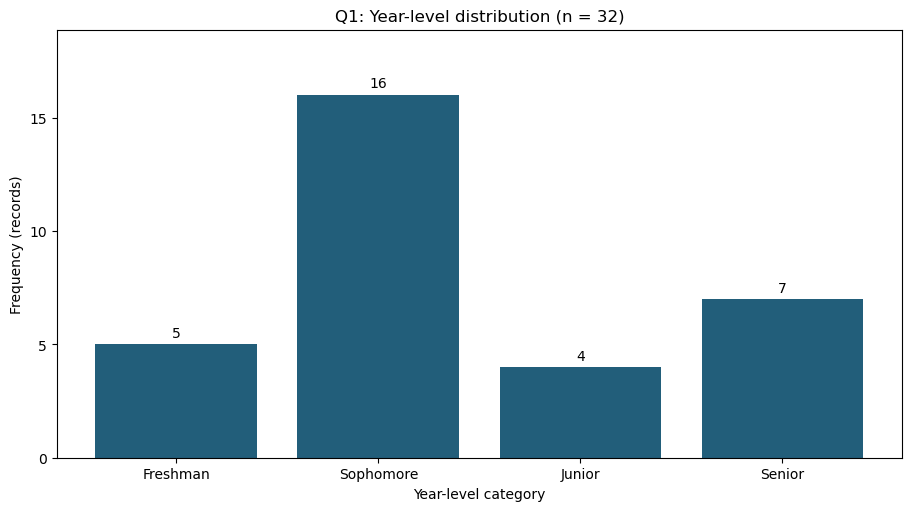

**Figure 2. Study-hour histogram.**

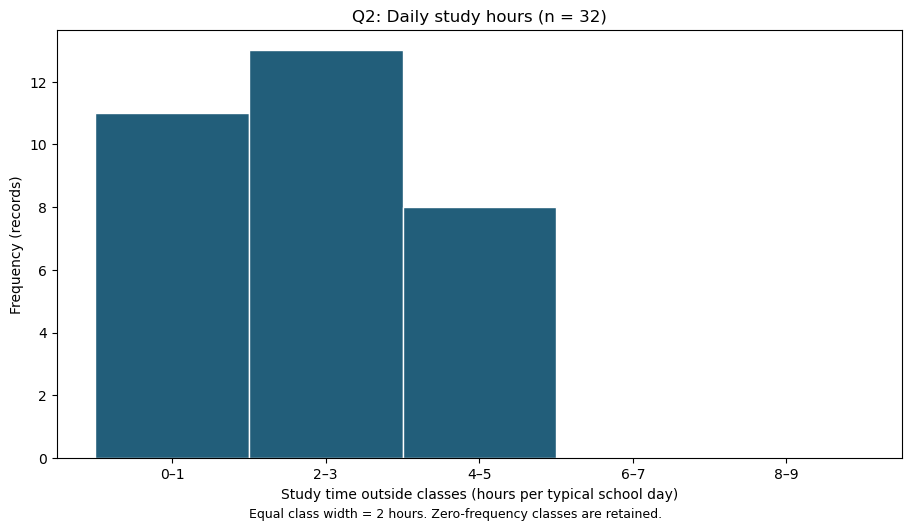

**Figure 3. Study-hour frequency polygon.**

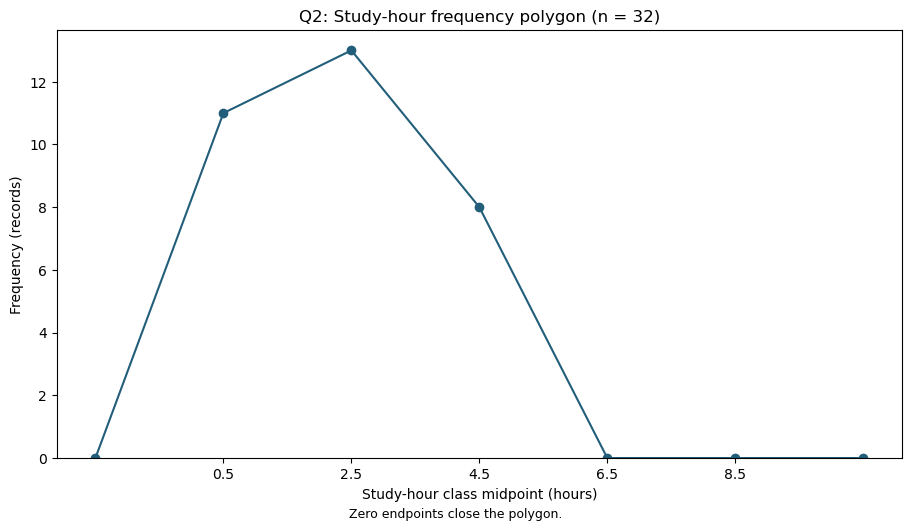

**Figure 4. Study-hour ogive.**

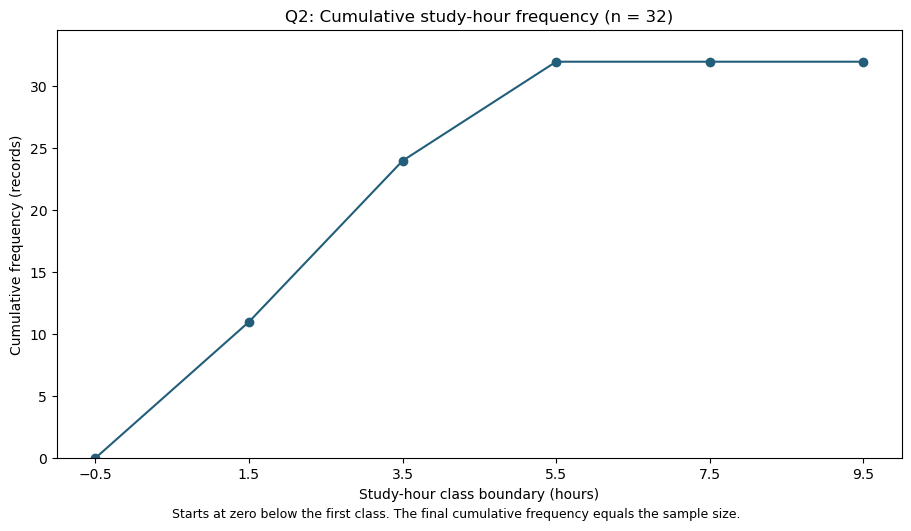

**Figure 5. One-way commute histogram.**

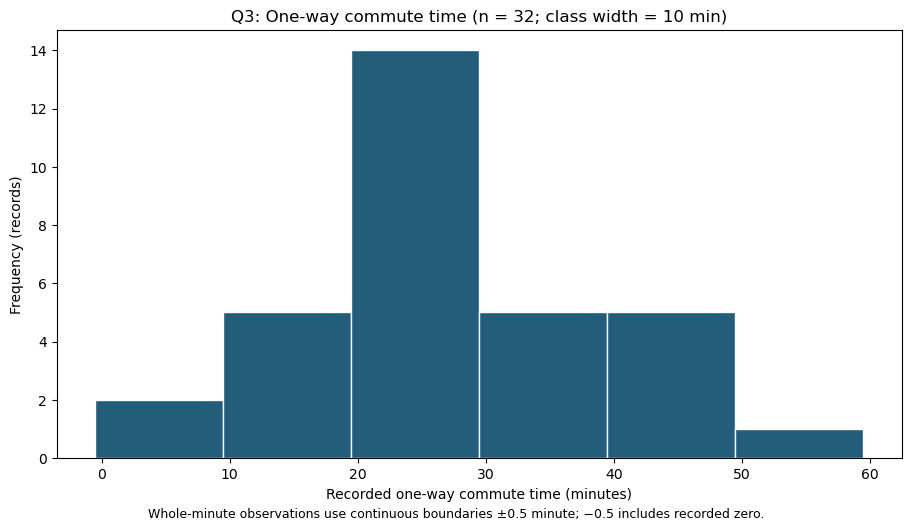

**Figure 6. One-way commute boxplot.**

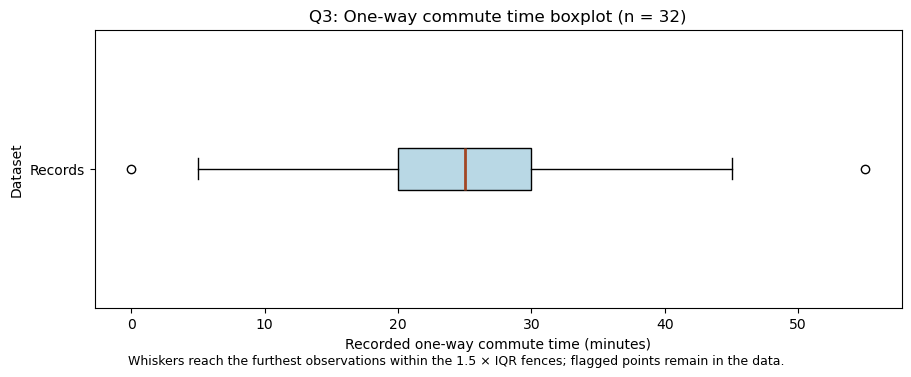

In [8]:
figure_order = [
    ("q1_year_level_bar", "Year-level bar chart"),
    ("q2_study_histogram", "Study-hour histogram"),
    ("q2_frequency_polygon", "Study-hour frequency polygon"),
    ("q2_ogive", "Study-hour ogive"),
    ("q3_commute_histogram", "One-way commute histogram"),
    ("q3_commute_boxplot", "One-way commute boxplot"),
]
for number, (key, caption) in enumerate(figure_order, 1):
    if key in result["figures"]:
        display(Markdown(f"**Figure {number}. {caption}.**"))
        display(result["figures"][key])

## 8. Interpretation, recommendation, and limitations

The mean reported study time is 2.34 hours per typical school day, with a median
of 2 hours. The most frequent answers are 1 and 2 hours (seven students each).
Commute has a mean of 25.16 minutes and a median of 25 minutes; the middle 50%
falls between 20 and 30 minutes, and the 90th percentile is 40 minutes.

Sophomores account for 16 of 32 respondents (50%). All four year levels are
represented, but their proportions cannot be judged representative without an
enrollment comparison. The grouped distributions have one main concentration;
moment skewness is slightly positive for both variables, without strong skew
under the declared 0.5 threshold. Neither finding establishes normality.

The findings support exploring study sessions attached to existing class days,
with a remote participation option to avoid extra journeys. They do not establish
preferred times or prove that commute duration causes a particular study pattern.

The main limitation is availability-based recruitment in a single building.
Self-report, whole-number recording, and the instrument's zero-for-walking rule
also limit interpretation. The zero-minute answer is valid under the survey rules;
its exact personal explanation was not recorded.

In [9]:
if result["n"]:
    s = result["statistics"]
    display(Markdown(
        f"Among the **{result['n']} respondents**, mean reported study time is "
        f"**{s.at['mean', 'study_hours']:.2f} hours/day**, and the median is "
        f"**{s.at['median', 'study_hours']:.2f} hours/day**. Mean one-way commute is "
        f"**{s.at['mean', 'commute_minutes']:.2f} minutes**, the median is "
        f"**{s.at['median', 'commute_minutes']:.2f} minutes**, and P90 is "
        f"**{s.at['p90', 'commute_minutes']:.2f} minutes**."
    ))
    METADATA = dict(METADATA)
    METADATA["recommendation"] = (
        f"The sample reports a median of {s.at['median', 'study_hours']:.0f} study hours/day and "
        f"a {s.at['median', 'commute_minutes']:.0f}-minute median one-way commute "
        f"(P90: {s.at['p90', 'commute_minutes']:.0f} minutes). Consider study-support sessions "
        "alongside existing classes, with a remote option to reduce additional travel. "
        "Confirm preferred times before setting a schedule; these summaries do not establish session demand."
    )
for label, key in [("Recommendation", "recommendation"), ("Vulnerable assumption", "vulnerable_assumption"), ("Next evidence", "next_evidence")]:
    display(Markdown(f"**{label}:** " + METADATA[key]))

Among the **32 respondents**, mean reported study time is **2.34 hours/day**, and the median is **2.00 hours/day**. Mean one-way commute is **25.16 minutes**, the median is **25.00 minutes**, and P90 is **40.00 minutes**.

**Recommendation:** The sample reports a median of 2 study hours/day and a 25-minute median one-way commute (P90: 40 minutes). Consider study-support sessions alongside existing classes, with a remote option to reduce additional travel. Confirm preferred times before setting a schedule; these summaries do not establish session demand.

**Vulnerable assumption:** Convenience sampling at one building may not represent all enrolled undergraduates; sophomores make up half the sample. The exam calls for probability sampling.

**Next evidence:** Repeat collection with a probability sample across year levels and campus locations, and ask about preferred study-session times.

## 9. Cover page and report

The PDF begins with an unnumbered cover page containing the student and course
details from `COVER_DETAILS`. The three analysis pages follow and retain their
own page numbering.

The report includes the collection location, date, sampling method, frequency
distributions, statistics, all six figures, recommendation, limitations, and
references. Chart images are also saved separately as PNG files.

Enter the student's full name before exporting the personalized cover; optional
fields such as section and submission date can be included when supplied.

In [10]:
"""Render a three-page analysis, optionally preceded by a personal cover page.

This module only formats results from ``survey_analysis.analyze``. It never
creates respondents or supplies missing collection details.
"""

from __future__ import annotations

from datetime import date
from io import BytesIO
from pathlib import Path
import re
import tempfile

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.font_manager import FontProperties
from matplotlib.text import Text


_WIDTH, _HEIGHT = 8.2677, 11.6929
_INK = "#203448"
_ACCENT = "#176b79"
_MUTED = "#536477"
_REQUIRED = (
    "population", "rounding_rule", "decision_question", "recommendation",
    "vulnerable_assumption", "next_evidence",
)
_REAL_REQUIRED = (
    "sampling_method", "selection_procedure", "collection_start", "collection_end",
)
_LIMITS = {
    "population": 250, "decision_question": 330, "selection_procedure": 750,
    "rounding_rule": 240, "recommendation": 650,
    "vulnerable_assumption": 350, "next_evidence": 350,
    "collection_note": 300,
}
_COVER_DEFAULTS = {
    "institution": "Cor Jesu College",
    "course": "Engineering Data Analysis",
    "instructor": "Engr. Jamie Eduardo Rosal, MSCpE",
}
_COVER_LIMITS = {
    "student_name": 120, "program": 180, "year_section": 120,
    "course": 120, "course_code": 60, "instructor": 140,
    "submission_date": 80, "institution": 120,
}
_PLACEHOLDER = re.compile(
    r"\b(?:TODO|TBD|TBC|placeholder|YYYY|insert here|fill in|your answer)\b"
    r"|<[^>]+>|\[[^\]]*(?:term|date|insert|enter|name)[^\]]*\]",
    re.IGNORECASE,
)
_FIGURES = (
    ("q1_year_level_bar", "Year-level frequencies"),
    ("q2_study_histogram", "Recorded daily study hours"),
    ("q2_frequency_polygon", "Study-hour frequency polygon"),
    ("q2_ogive", "Study-hour cumulative frequencies"),
    ("q3_commute_histogram", "Recorded one-way commute times"),
    ("q3_commute_boxplot", "Commute distribution and outliers"),
)
_METRICS = (
    ("mean", "Mean"), ("median", "Median"), ("modes", "Mode(s)"),
    ("minimum", "Minimum"), ("maximum", "Maximum"), ("range", "Range"),
    ("sample_variance", "Sample variance (squared units)"),
    ("sample_sd", "Sample standard deviation"),
    ("q1", "First quartile (Q1)"), ("q3", "Third quartile (Q3)"),
    ("iqr", "Interquartile range (IQR)"),
    ("p10", "10th percentile (P10)"), ("p90", "90th percentile (P90)"),
    ("lower_fence", "Lower outlier fence"), ("upper_fence", "Upper outlier fence"),
)


def _documented_survey(metadata: dict) -> bool:
    return str(metadata.get("report_type", "descriptive")).strip().lower() == "survey"


def _cover_metadata(metadata: dict) -> dict | None:
    if "cover" not in metadata:
        return None
    supplied = metadata["cover"]
    return {**_COVER_DEFAULTS, **supplied} if isinstance(supplied, dict) else None


def report_readiness(result: dict, metadata: dict) -> list[str]:
    """Return specific blockers; an empty list means report export can proceed.

    Descriptive reports summarize the available dataset. Documented survey
    reports additionally require the actual sampling method, selection details,
    and completed collection dates.
    """
    problems = []
    if "cover" in metadata:
        if not isinstance(metadata["cover"], dict):
            problems.append("metadata['cover'] must be a dictionary when a cover page is requested.")
        else:
            cover = _cover_metadata(metadata)
            student_name = cover.get("student_name", "")
            if not isinstance(student_name, str) or not student_name.strip():
                problems.append("Complete metadata['cover']['student_name'] before exporting a personal cover page.")
            for key, limit in _COVER_LIMITS.items():
                value = cover.get(key, "")
                if not isinstance(value, str):
                    problems.append(f"metadata['cover']['{key}'] must be text when supplied.")
                elif len(value) > limit:
                    problems.append(f"Shorten metadata['cover']['{key}'] to at most {limit} characters.")
                elif _PLACEHOLDER.search(value):
                    problems.append(f"Replace the template text in metadata['cover']['{key}'].")
    try:
        n = int(result.get("n", 0))
    except (TypeError, ValueError):
        n = 0
    if n < 30:
        problems.append(f"At least 30 valid records are required; only {n} are available.")
    report_type = str(metadata.get("report_type", "descriptive")).strip().lower()
    if report_type not in {"descriptive", "survey"}:
        problems.append("metadata['report_type'] must be 'descriptive' or 'survey'.")
    documented_survey = _documented_survey(metadata)
    required = _REQUIRED + _REAL_REQUIRED if documented_survey else _REQUIRED
    for key in required:
        value = metadata.get(key)
        if not isinstance(value, str) or not value.strip() or value.strip().lower() in {"n/a", "na", "none", "not collected"}:
            problems.append(f"Complete metadata['{key}'] with the required details.")
        elif _PLACEHOLDER.search(value):
            problems.append(f"Replace the template text in metadata['{key}'].")
    collection_note = metadata.get("collection_note", "")
    if not isinstance(collection_note, str):
        problems.append("metadata['collection_note'] must be text when supplied.")
    elif _PLACEHOLDER.search(collection_note):
        problems.append("Replace the template text in metadata['collection_note'].")
    for key, limit in _LIMITS.items():
        value = metadata.get(key, "")
        if isinstance(value, str) and len(value) > limit:
            problems.append(f"Shorten metadata['{key}'] to at most {limit} characters for the three-page report.")
    if documented_survey:
        if str(metadata.get("sampling_method", "")).strip().lower() not in {"random", "systematic", "stratified", "cluster", "convenience"}:
            problems.append("sampling_method must be random, systematic, stratified, cluster, or convenience, and must describe the method actually used.")
        parsed = {}
        for key in ("collection_start", "collection_end"):
            value = metadata.get(key, "")
            try:
                if not re.fullmatch(r"\d{4}-\d{2}-\d{2}", value):
                    raise ValueError
                parsed[key] = date.fromisoformat(value)
                if parsed[key] > date.today():
                    problems.append(f"{key} is in the future; enter the completed collection date.")
            except (ValueError, TypeError):
                problems.append(f"metadata['{key}'] must be a completed date in YYYY-MM-DD format.")
        if len(parsed) == 2 and parsed["collection_end"] < parsed["collection_start"]:
            problems.append("collection_end must not precede collection_start.")
    if "valid" not in result or len(result["valid"]) != n:
        problems.append("The valid-row count does not match result['n']; rerun the analysis.")
    for key in ("raw", "excluded", "statistics", "outliers", "shapes"):
        if key not in result:
            problems.append(f"Missing analysis result '{key}'; rerun the analysis.")
    for key in ("q1", "q2", "q3"):
        table = result.get("tables", {}).get(key)
        expected = {"category" if key == "q1" else "class_interval", "frequency", "percent", "cumulative_frequency"}
        if table is None or not expected.issubset(table.columns):
            problems.append(f"Missing or incomplete {key} frequency table; rerun the analysis.")
        elif len(table) > (10 if key != "q3" else 8):
            problems.append(f"The {key} table has too many classes for this three-page layout; use at most {'8' if key == 'q3' else '10'} classes.")
    statistics = result.get("statistics")
    if statistics is not None:
        expected_metrics = {key for key, _ in _METRICS}
        if not expected_metrics.issubset(statistics.index) or not {"study_hours", "commute_minutes"}.issubset(statistics.columns):
            problems.append("The descriptive-statistics table is incomplete; rerun the analysis.")
    for key, _ in _FIGURES:
        if key not in result.get("figures", {}):
            problems.append(f"Missing figure '{key}'; rerun the analysis.")
    return problems


class _Page:
    def __init__(self, number: int, title: str, *, decorated=True):
        self.fig = plt.figure(figsize=(_WIDTH, _HEIGHT), facecolor="white")
        self.canvas = FigureCanvasAgg(self.fig)
        self.canvas.draw()
        self.renderer = self.canvas.get_renderer()
        if not decorated:
            return
        self.text(.45, .35, 7.36, .32, title, size=17, minimum=17, weight="bold")
        label = "COR JESU COLLEGE | DESCRIPTIVE STATISTICS REPORT"
        self.text(.45, .85, 7.36, .27, label, size=10, minimum=10,
                  weight="bold", color=_ACCENT)
        self.fig.add_artist(plt.Line2D([.45 / _WIDTH, 7.82 / _WIDTH], [1 - 1.22 / _HEIGHT] * 2,
                                      transform=self.fig.transFigure, color="#b9cbd1", linewidth=.8))
        footer = "Descriptive results for this dataset; population conclusions require appropriate sampling."
        self.text(.45, 11.12, 6.8, .22, footer, size=7.5, minimum=7.5, color=_MUTED)
        self.text(7.25, 11.12, .55, .22, f"{number} / 3", size=8, minimum=8, color=_MUTED)

    def _wrap(self, text: str, width: float, size: float, weight: str) -> str:
        font = FontProperties(family="DejaVu Sans", size=size, weight=weight)
        pixel_width = width * self.fig.dpi
        lines = []
        for paragraph in str(text).split("\n"):
            line = ""
            for word in paragraph.split():
                candidate = f"{line} {word}".strip()
                measured = self.renderer.get_text_width_height_descent(candidate, font, ismath=False)[0]
                if measured <= pixel_width:
                    line = candidate
                else:
                    if line:
                        lines.append(line)
                    if self.renderer.get_text_width_height_descent(word, font, ismath=False)[0] > pixel_width:
                        raise ValueError("A report field contains an unbroken word too wide to print; shorten it.")
                    line = word
            lines.append(line)
        return "\n".join(lines)

    def text(self, x, y, width, height, content, *, size=9, minimum=8.3, weight="normal", color=_INK, align="left"):
        candidate = size
        while candidate >= minimum - .01:
            wrapped = self._wrap(str(content), width, candidate, weight)
            anchor_x = x + (width / 2 if align == "center" else width if align == "right" else 0)
            artist = self.fig.text(anchor_x / _WIDTH, 1 - y / _HEIGHT, wrapped, va="top", ha=align,
                                   fontsize=candidate, fontfamily="DejaVu Sans", fontweight=weight,
                                   color=color, linespacing=1.2)
            bounds = artist.get_window_extent(self.renderer)
            if bounds.height <= height * self.fig.dpi + 1 and bounds.width <= width * self.fig.dpi + 1:
                return
            artist.remove()
            candidate -= .2
        raise ValueError(f"Report text exceeds the three-page layout. Shorten this field or narrative: {str(content)[:95]!r}")

    def heading(self, y, title):
        self.text(.45, y, 7.36, .28, title, size=11, minimum=11, weight="bold", color=_ACCENT)

    def table(self, x, y, width, height, headers, rows, col_widths=None, fontsize=8.2):
        ax = self.fig.add_axes([x / _WIDTH, 1 - (y + height) / _HEIGHT, width / _WIDTH, height / _HEIGHT])
        ax.set_axis_off()
        table = ax.table(cellText=rows, colLabels=headers, colWidths=col_widths,
                         cellLoc="right", colLoc="center", bbox=[0, 0, 1, 1])
        table.auto_set_font_size(False)
        table.set_fontsize(fontsize)
        for (row, col), cell in table.get_celld().items():
            cell.set_edgecolor("#d7e1e5")
            cell.set_linewidth(.45)
            cell.PAD = .05
            cell.set_facecolor("#e5f0f2" if row == 0 else ("#f4f7f8" if row % 2 == 0 else "white"))
            cell.get_text().set_color(_INK)
            if row == 0:
                cell.get_text().set_weight("bold")
            if col == 0:
                cell.get_text().set_ha("left")
            available = width * (col_widths[col] if col_widths else 1 / len(headers)) - .09
            cell.get_text().set_text(self._wrap(cell.get_text().get_text(), available, fontsize,
                                                "bold" if row == 0 else "normal"))
        self.canvas.draw()
        for cell in table.get_celld().values():
            text_bounds = cell.get_text().get_window_extent(self.renderer)
            cell_bounds = cell.get_window_extent(self.renderer)
            if text_bounds.height > cell_bounds.height - 1 or text_bounds.width > cell_bounds.width - 1:
                raise ValueError("A frequency/statistics table does not fit legibly. Shorten long labels or reduce the number of classes.")

    def chart(self, x, y, width, height, figure, number, caption, *, capped=False):
        self.text(x, y, width, .22, f"Figure {number}. {caption}", size=8.7, minimum=8.3,
                  weight="bold", color=_ACCENT)
        raster = _chart_image(figure, width, height - .25, number, capped=capped)
        ax = self.fig.add_axes([x / _WIDTH, 1 - (y + height) / _HEIGHT, width / _WIDTH, (height - .25) / _HEIGHT])
        ax.imshow(raster, aspect="equal")
        ax.set_axis_off()


def _chart_image(figure, width, height, number, *, capped=False):
    """Render at the destination size, restoring the caller's figure afterward."""
    old_size = figure.get_size_inches().copy()
    texts = [(item, item.get_fontsize(), item.get_text(), item.get_visible(),
              item.get_rotation(), item.get_ha()) for item in figure.findobj(Text)]
    positions = [(axis, axis.get_position().frozen()) for axis in figure.axes]
    original_y_ticks = [(axis, axis.get_yticks(), [item.get_text() for item in axis.get_yticklabels()])
                        for axis in figure.axes]
    layout = figure.get_layout_engine()
    try:
        figure.set_layout_engine(None)
        figure.set_size_inches(width, height, forward=False)
        for item, *_ in texts:
            item.set_fontsize(8)
        for item in figure.texts:
            # Original plot footnotes are stated in the surrounding report text.
            item.set_visible(False)
        for axis in figure.axes:
            original_title = axis.get_title()
            sample = re.search(r"n\s*=\s*\d+", original_title)
            axis.set_title(sample.group(0) if sample else "Valid records")
            axis.title.set_fontsize(8.2)
            axis.set_xlabel({
                1: "Year-level category",
                2: "Recorded study score (hours; 8 = 8+)" if capped else "Study time (hours per school day)",
                3: "Score-class midpoint (hours)" if capped else "Class midpoint (hours)",
                4: "Score-class boundary (hours)" if capped else "Class boundary (hours)",
                5: "One-way commute (minutes)", 6: "One-way commute (minutes)",
            }[number])
            axis.set_ylabel("Cumulative\ncount (records)" if number == 4 else ("" if number == 6 else "Count (records)"))
            if number == 6:
                axis.set_yticks([1], ["Records"])
            if number == 1:
                for item in axis.get_xticklabels():
                    item.set_rotation(22)
                    item.set_ha("right")
            if number == 2 and capped:
                labels = axis.get_xticklabels()
                for item in labels:
                    if "8" in item.get_text() and "score" in item.get_text():
                        item.set_text("8-9 (8+)")
                # Fixed labels must be updated on the locator as well as artists.
                axis.set_xticks(axis.get_xticks(), [item.get_text() for item in labels])
            # Insets leave room for labels even when four charts share a page.
            axis.set_position([.18, .29, .78, .54] if height < 2.1 else [.18, .22, .78, .67])
        buffer = BytesIO()
        figure.savefig(buffer, format="png", dpi=180, facecolor="white")
        buffer.seek(0)
        return mpimg.imread(buffer)
    finally:
        figure.set_size_inches(old_size, forward=False)
        for item, fontsize, content, visible, rotation, alignment in texts:
            item.set_fontsize(fontsize)
            item.set_text(content)
            item.set_visible(visible)
            item.set_rotation(rotation)
            item.set_ha(alignment)
        # Replacing a fixed tick formatter needs explicit restoration.
        if number == 2 and capped:
            for axis in figure.axes:
                labels = [content for item, _, content, *_ in texts if item in axis.get_xticklabels()]
                if len(labels) == len(axis.get_xticks()):
                    axis.set_xticks(axis.get_xticks(), labels)
        if number == 6:
            for axis, ticks, labels in original_y_ticks:
                axis.set_yticks(ticks, labels)
        for axis, position in positions:
            axis.set_position(position)
        figure.set_layout_engine(layout)


def _frequency_rows(table, label):
    return [[str(row[label]), str(int(row["frequency"])), f"{float(row['percent']):.1f}%",
             str(int(row["cumulative_frequency"]))] for _, row in table.iterrows()]


def _value(value):
    if isinstance(value, str):
        return "None (all unique)" if value.startswith("No mode") else value
    return f"{float(value):,.2f}"


def _outliers(result):
    counts = [len(result["outliers"].get(key, [])) for key in ("study_hours", "commute_minutes")]
    summary = f"The 1.5 x IQR rule flags {counts[0]} study-hour and {counts[1]} commute record(s). "
    valid = result["valid"].set_index("respondent_id")
    for key, label, unit in (("study_hours", "Study-hour", "h"), ("commute_minutes", "Commute", "min")):
        identifiers = result["outliers"].get(key, [])
        if 0 < len(identifiers) <= 3:
            details = [f"ID {identifier} = {float(valid.loc[identifier, key]):g} {unit}" for identifier in identifiers]
            summary += f"{label} flags: " + "; ".join(details) + ". "
    summary += "Flagged values are retained for review."
    if any(float(valid.loc[identifier, "commute_minutes"]) == 0
           for identifier in result["outliers"].get("commute_minutes", [])):
        summary += " The 0-minute value is allowed by the survey rule and is retained."
    return summary


def _shape_summary(description):
    # The engine's following sentences repeat caveats already printed here.
    return description.split(". ", 1)[0].rstrip(".") + "."


def _cover_page(cover):
    page = _Page(0, "", decorated=False)
    left, width = .70, _WIDTH - 1.40

    def line(y, height, value, *, size=11, minimum=9.5, weight="normal", color=_INK):
        if value.strip():
            page.text(left, y, width, height, value.strip(), size=size, minimum=minimum,
                      weight=weight, color=color, align="center")

    line(.84, .55, cover.get("institution", ""), size=16, minimum=13, weight="bold", color=_ACCENT)
    line(1.54, .55, cover.get("course", ""), size=12, minimum=10.6)
    line(2.10, .30, cover.get("course_code", ""), size=10.4, minimum=9.4, color=_MUTED)
    page.fig.add_artist(plt.Line2D([left / _WIDTH, (left + width) / _WIDTH], [1 - 2.65 / _HEIGHT] * 2,
                                   transform=page.fig.transFigure, color=_ACCENT, linewidth=1.3))
    line(3.10, 1.12, "Study Habits and\nTravel to Campus", size=29, minimum=25, weight="bold")
    line(4.49, .36, "TAKE-HOME APPLIED EXAM  |  CHAPTERS 1–3", size=10.5, minimum=9.8, color=_ACCENT)

    line(5.65, .28, "SUBMITTED BY", size=9, minimum=9, weight="bold", color=_ACCENT)
    line(6.04, .68, cover["student_name"], size=17, minimum=13, weight="bold")
    detail_y = 6.89
    for key in ("program", "year_section"):
        value = cover.get(key, "")
        if value.strip():
            line(detail_y, .55, value, size=11, minimum=9.5, color=_MUTED)
            detail_y += .57
    instructor = cover.get("instructor", "")
    if instructor.strip():
        line(8.43, .28, "SUBMITTED TO", size=9, minimum=9, weight="bold", color=_ACCENT)
        line(8.83, .61, instructor, size=12, minimum=10.2)
    submission_date = cover.get("submission_date", "")
    if submission_date.strip():
        line(10.00, .28, "SUBMISSION DATE", size=9, minimum=9, weight="bold", color=_ACCENT)
        line(10.39, .45, submission_date, size=11, minimum=9.5)
    return page


def _page_one(result, metadata):
    page = _Page(1, "Study habits and travel to campus")
    page.heading(1.42, "1  Decision question")
    page.text(.45, 1.77, 7.36, .63, metadata["decision_question"], size=10)
    page.heading(2.48, "2  Sample, method, and measurement")
    n = result["n"]
    capped = result.get("topcoded_count", 0) > 0
    total, excluded = len(result["raw"]), len(result["excluded"])
    if _documented_survey(metadata):
        method = (f"Population: {metadata['population']}\n"
                  f"Sample: {n} valid respondents from {total} submitted records; {excluded} excluded by validation. "
                  f"Collection: {metadata['collection_start']} to {metadata['collection_end']}. "
                  f"Sampling method: {metadata['sampling_method'].strip().lower()}. {metadata['selection_procedure']}")
    else:
        method = (f"Analysis includes {n} complete records from {total} input rows; {excluded} excluded by validation. "
                  + (metadata.get("collection_note", "").strip() + " " if metadata.get("collection_note", "").strip() else "")
                  + f"Intended study population: {metadata['population']}")
    study_definition = "Q2 records discrete study hours. "
    if capped:
        study_definition += "The open-ended 8+ answer is scored as 8, a lower bound. "
    method += ("\nA statistic describes these records (for example, their mean); a parameter describes the whole target population. "
               "These records do not establish the population mean.\n"
               "Q1 is ordinal categorical. " + study_definition +
               "Q3 is continuous time recorded in whole minutes. Hours and minutes use ratio scales; "
               "the survey codes walking/on-campus travel as 0.\n"
               f"Rounding: {metadata['rounding_rule']}")
    study_table = result["tables"]["q2"]
    study_width = float(study_table.iloc[0]["upper_boundary"] - study_table.iloc[0]["lower_boundary"])
    midpoints = ", ".join(f"{float(value):g}" for value in study_table["midpoint"])
    commute_table = result["tables"]["q3"]
    width = float(commute_table.iloc[0]["upper_boundary"] - commute_table.iloc[0]["lower_boundary"])
    cap_note = " (the last class contains capped scores)" if capped else ""
    method += (f"\nGrouping: Q2 class width {study_width:g} h; midpoints {midpoints}{cap_note}. "
               f"Q3 width {width:g} min; whole-minute limits have boundaries +/-0.5 min. Midpoint = (lower + upper boundary) / 2.")
    page.text(.45, 2.84, 7.36, 2.55, method, size=9)
    page.heading(5.56, "3  Frequency distributions")
    page.text(.45, 5.94, 3.52, .23, "Q1: Year level", size=9, weight="bold")
    page.text(4.16, 5.94, 3.65, .23, "Q2: Study hours (8 = 8+ score)" if capped else "Q2: Study hours", size=9, weight="bold")
    headers = ["Category", "f", "Rel. %", "Cum. f"]
    page.table(.45, 6.25, 3.52, 2.24, headers, _frequency_rows(result["tables"]["q1"], "category"),
               [.52, .12, .19, .17], fontsize=7.9)
    page.table(4.16, 6.25, 3.65, 2.24, ["Hours / class", "f", "Rel. %", "Cum. f"],
               _frequency_rows(result["tables"]["q2"], "class_interval"), [.49, .12, .21, .18], fontsize=7.9)
    page.text(.45, 8.71, 7.36, .23, "Q3: One-way commute time (minutes)", size=9, weight="bold")
    page.table(.45, 9.02, 7.36, 1.48, ["Minute class", "Frequency", "Relative %", "Cumulative f"],
               _frequency_rows(result["tables"]["q3"], "class_interval"), [.40, .20, .20, .20], fontsize=8.1)
    page.text(.45, 10.65, 7.36, .31,
              f"All three tables use n = {n}; relative frequency = f / n. Percentages may differ from 100% by rounding. "
              "Cumulative year-level counts follow form order only.", size=7.9, minimum=7.9, color=_MUTED)
    return page


def _page_two(result, metadata):
    page = _Page(2, "Description of the recorded values")
    page.heading(1.42, "4  Descriptive statistics and first two figures")
    year = result["tables"]["q1"]
    largest = int(year["frequency"].max())
    common = ", ".join(year.loc[year["frequency"].eq(largest), "category"])
    absent = ", ".join(year.loc[year["frequency"].eq(0), "category"]) or "none"
    page.text(.45, 1.79, 7.36, 1.01,
              "Statistics below use ungrouped valid records. Figures 1 and 2 show year-level composition and recorded study hours. "
              f"Most common year level(s): {common} ({largest} each). Missing year-level categories: {absent}. "
              "Sample variance and standard deviation use n - 1. Inclusive linear quantiles match Sheets INC; "
              "Bluman section 3-3 hand rules may differ.", size=9)
    statistics = result["statistics"]
    rows = [[label, _value(statistics.loc[key, "study_hours"]), _value(statistics.loc[key, "commute_minutes"])]
            for key, label in _METRICS]
    page.table(.45, 3.00, 7.36, 2.67, ["Statistic", "Study hours (h)", "Commute time (min)"], rows,
               [.45, .275, .275], fontsize=8.2)
    capped = result.get("topcoded_count", 0) > 0
    study_note = (f"{result['topcoded_count']} record(s) selected 8+. Study summaries describe capped scores and can understate actual hours. "
                  if capped else "All study-hour answers are finite whole-hour values; no open-ended answer occurs. ")
    page.text(.45, 5.83, 7.36, .65, study_note + _outliers(result), size=8.5)
    page.chart(.45, 6.77, 3.61, 3.97, result["figures"][_FIGURES[0][0]], 1, _FIGURES[0][1])
    page.chart(4.20, 6.77, 3.61, 3.97, result["figures"][_FIGURES[1][0]], 2, _FIGURES[1][1], capped=capped)
    return page


def _page_three(result, metadata):
    page = _Page(3, "Patterns, decision, and limitations")
    capped = result.get("topcoded_count", 0) > 0
    page.text(.45, 1.43, 7.36, .85,
              "Figures 3 and 4 show study-hour frequencies and cumulative counts; Figures 5 and 6 show commute shape and IQR outliers. "
              f"Study hours: {_shape_summary(result['shapes']['q2'])} Commute: {_shape_summary(result['shapes']['q3'])} "
              "These are not normality tests. The polygon closes at zero; the ogive starts at zero below the first class.", size=8.5)
    for index, (x, y) in enumerate(((.45, 2.32), (4.20, 2.32), (.45, 4.63), (4.20, 4.63)), start=2):
        key, caption = _FIGURES[index]
        page.chart(x, y, 3.61, 2.12, result["figures"][key], index + 1, caption, capped=capped)
    page.heading(6.98, "5  Recommendation")
    page.text(.45, 7.32, 7.36, 1.08, metadata["recommendation"], size=9)
    page.heading(8.56, "6  Limitations and next evidence")
    measurement_limits = ("Self-report, study-hour top-coding, and the zero-for-walking rule limit interpretation. "
                          if capped else "Self-report and the zero-for-walking rule limit interpretation. ")
    limitations = (f"Most vulnerable assumption: {metadata['vulnerable_assumption']} "
                   f"Next evidence: {metadata['next_evidence']} "
                   + measurement_limits +
                   "Descriptive associations do not establish cause and effect.")
    page.text(.45, 8.91, 7.36, 1.24, limitations, size=8.5)
    page.text(.45, 10.34, 7.36, .53,
              "References: Allan G. Bluman (2012), Elementary Statistics: A Step by Step Approach, 8th ed., McGraw-Hill; sections 1-1, 1-2, 1-3; "
              "2-1, 2-2, 2-3; 3-1, 3-2, 3-3, 3-4. Cor Jesu College applied exam and supplied survey form.",
              size=7.8, minimum=7.8, color=_MUTED)
    return page


def export_report(result: dict, metadata: dict, path: str | Path) -> Path:
    """Save three A4 analysis pages and an optional cover, with no partial PDF."""
    problems = report_readiness(result, metadata)
    if problems:
        raise ValueError("Report is not ready:\n- " + "\n- ".join(problems))
    destination = Path(path).expanduser().resolve()
    if destination.suffix.lower() != ".pdf":
        raise ValueError("Report output must have a .pdf extension.")
    destination.parent.mkdir(parents=True, exist_ok=True)
    pages = []
    temporary = None
    existing_figures = set(plt.get_fignums())
    try:
        cover = _cover_metadata(metadata)
        if cover is not None:
            pages.append(_cover_page(cover))
        for build in (_page_one, _page_two, _page_three):
            pages.append(build(result, metadata))
        with tempfile.NamedTemporaryFile(prefix=".survey-report-", suffix=".pdf", dir=destination.parent, delete=False) as handle:
            temporary = Path(handle.name)
        with PdfPages(temporary) as pdf:
            pdf.infodict()["Title"] = "Cor Jesu College descriptive statistics report"
            pdf.infodict()["Subject"] = "Three-page descriptive statistics report"
            if cover is not None:
                pdf.infodict()["Author"] = cover["student_name"].strip()
            for page in pages:
                pdf.savefig(page.fig)
        temporary.replace(destination)
        return destination
    finally:
        for number in set(plt.get_fignums()) - existing_figures:
            plt.close(number)
        if temporary is not None and temporary.exists():
            temporary.unlink()

In [11]:
pending = report_readiness(result, METADATA)
if pending:
    print("Report not generated. Complete these items:")
    for item in pending:
        print("•", item)
else:
    report_name = "Cor_Jesu_EDA_Report.pdf"
    report_path = export_report(result, METADATA, OUTPUT_DIR / report_name)
    display(Markdown(f"[Open the analysis report]({report_path.relative_to(Path.cwd()).as_posix()})"))

print("Tables, validation notes, outlier flags, and separate chart images:", OUTPUT_DIR.as_posix())

[Open the analysis report](analysis_output/Cor_Jesu_EDA_Report.pdf)

Tables, validation notes, outlier flags, and separate chart images: analysis_output


## 10. Submission checklist and references

- The supplied dataset contains 32 complete anonymous responses; all are retained.
  Check the transcription against the original response sheet.
- Collection is documented as convenience sampling in the lobby of Norbert Building on
  14 October 2026. The exam requires probability sampling; follow-up data collection
  is needed to satisfy that specific requirement. Keep the enumerator log.
- Select the input CSV and complete the report metadata. Run every cell from the
  top; check that frequencies sum to n and inspect excluded rows.
- Review the three frequency distributions; all six graphs; both sets of numerical
  summaries; outlier flags; and the representation of the four year-level categories.
- Revise your explanation, recommendation, limitations, and references in your own
  words. Review the generated PDF for readability and keep the analysis within three pages, with the cover separate.
- Submit the executed `.ipynb`, selected CSV and dictionary for reproducibility,
  the final report PDF, and the six separate chart images according to your instructor's
  instructions, using the documented collected data. Complete the supplied student
  declaration yourself only if it is accurate.

**References:** Bluman, A. G. (2012). *Elementary Statistics: A Step by Step Approach*
(8th ed.). McGraw-Hill. Classroom textbook: §§1-1–1-3
(statistical concepts, variables, data collection and sampling), §§2-1–2-3
(frequency distributions, histograms, polygons, ogives, and other graphs), and
§§3-1–3-4 (center, variation, position, and exploratory data analysis).
The supplied Cor Jesu exam and printed instrument determine the survey wording,
response categories, tool requirements, and submission checklist.